link = https://youtu.be/csaI2LqQ9ns

In [1]:
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

from pacman_rl import ACTIONS, MAZE, Maze, evaluate, export_policy, greedy, self_check, train

self_check()
print("\n".join(MAZE))
example = Maze(42)
print("Contoh state awal:", example.observe()[0])
print("Arah valid:", [ACTIONS[action] for action in example.actions()])

###########
#.........#
#.#.#.###.#
#...#.....#
###...#.#.#
#...#.....#
#.#.#.##..#
#.#...#...#
#...#...#.#
#.........#
###########
Contoh state awal: 7:0:0:0:1:2
Arah valid: ['up', 'right', 'down']


Seed 42 selesai. 1230 state dipelajari.


Seed 43 selesai. 1234 state dipelajari.


Seed 44 selesai. 1233 state dipelajari.


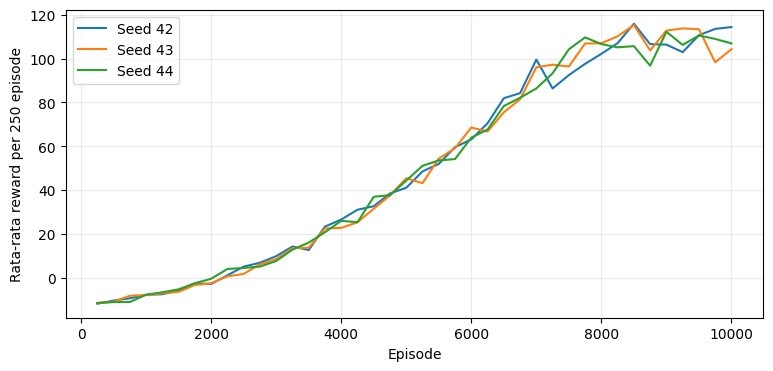

In [2]:
train_seeds = (42, 43, 44)
episode_count = 10_000
models = {}
histories = {}

for seed in train_seeds:
    models[seed], histories[seed] = train(seed, episode_count)
    print(f"Seed {seed} selesai. {len(models[seed])} state dipelajari.")

window = 250
ends = range(window, episode_count + 1, window)
fig, ax = plt.subplots(figsize=(9, 4))
for seed, returns in histories.items():
    ax.plot(ends, [mean(returns[end-window:end]) for end in ends], label=f"Seed {seed}")
ax.set(xlabel="Episode", ylabel="Rata-rata reward per 250 episode")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

In [3]:
evaluation_seeds = range(1_000_000_000, 1_000_000_100)
baseline = evaluate(None, evaluation_seeds)
learned = {seed: evaluate(model, evaluation_seeds) for seed, model in models.items()}

print(f"{'Policy':<16} {'Skor':>8} {'Pellet':>8} {'Power':>8} {'Buah':>8} {'Hantu':>8} {'Maze selesai':>14} {'Tertangkap':>12} {'Langkah':>8}")
for label, rows in [("Acak", baseline), *[(f"Q-learning {seed}", rows) for seed, rows in learned.items()]]:
    metrics = [mean(row[key] for row in rows) for key in ("score", "pellets", "power", "fruit", "ghosts")]
    cleared = 100 * mean(row["outcome"] == "cleared" for row in rows)
    caught = 100 * mean(row["outcome"] == "caught" for row in rows)
    steps = mean(row["steps"] for row in rows)
    print(f"{label:<16}" + "".join(f"{value:>8.2f}" for value in metrics) + f"{cleared:>13.1f}% {caught:>11.1f}% {steps:>8.1f}")

base_score = mean(row["score"] for row in baseline)
learned_score = mean(row["score"] for rows in learned.values() for row in rows)
print(f"Selisih rata-rata terhadap acak {learned_score - base_score:+.2f} poin per episode.")

Policy               Skor   Pellet    Power     Buah    Hantu   Maze selesai   Tertangkap  Langkah
Acak              144.30   10.79    0.51    0.10    0.03          0.0%       100.0%     31.3
Q-learning 42    1198.60   52.46    3.80    1.20    2.01          4.0%         0.0%    149.5
Q-learning 43    1216.20   53.18    3.76    1.32    2.01         13.0%         0.0%    147.2
Q-learning 44     985.70   52.21    3.79    0.92    1.10          6.0%         0.0%    149.1
Selisih rata-rata terhadap acak +989.20 poin per episode.


In [4]:
demo_seed = 42
policy_file = Path("extension/policy.json")
export_policy(models[demo_seed], policy_file)
print(f"Model seed {demo_seed} diekspor ke {policy_file}.")

example = Maze(42)
state, fallback, choices = example.observe()
table = models[demo_seed]
values = table.get(state)
if values is not None:
    print("Nilai Q untuk arah valid:", {ACTIONS[a]: round(values[a], 2) for a in example.actions()})
action = greedy(table, state, fallback, choices)
print(f"Contoh keputusan untuk state {state}: {ACTIONS[action]}, reward {example.step(action):+.2f}.")

Model seed 42 diekspor ke extension\policy.json.
Nilai Q untuk arah valid: {'up': 14.19, 'right': 15.93, 'down': 17.88}
Contoh keputusan untuk state 7:0:0:0:1:2: down, reward +0.98.
